# Partie 2 — Deep Learning : MLP PyTorch

Ce notebook implémente un **Perceptron Multicouches (MLP)** en PyTorch pour la classification binaire du défaut de crédit, et le compare aux modèles classiques de la Partie 1.

**Architecture choisie** : `80 → 64 → 32 → 1`, pyramidale, avec `ReLU + BatchNorm + Dropout`. Configuration d'entraînement : Adam, `BCEWithLogitsLoss` avec `pos_weight` (équivalent à `class_weight='balanced'`), batch=256, max 30 epochs, EarlyStopping(patience=5).

**Référence** : Gunnarsson et al., 2021 — *« Deep learning for credit scoring : do or don't ? »* — qui établit que sur données tabulaires, DL ≈ ML classique. Nous vérifions expérimentalement.

## 1. Imports et reproductibilité

In [1]:
import numpy as np
import torch
import torch.nn as nn
import time
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)
print('PyTorch', torch.__version__)

PyTorch 2.12.0+cpu


## 2. Chargement des données préparées

Les fichiers `.npy` sont produits par le notebook 01 (EDA + Preprocessing). Cette continuité garantit la cohérence du split train/test entre les deux parties.

In [1]:
X_train = np.load('../outputs/X_train.npy').astype(np.float32)
X_test  = np.load('../outputs/X_test.npy').astype(np.float32)
y_train = np.load('../outputs/y_train.npy').astype(np.float32)
y_test  = np.load('../outputs/y_test.npy').astype(np.float32)
print(f'X_train : {X_train.shape} | défauts : {y_train.mean():.2%}')
print(f'X_test  : {X_test.shape}')
n_features = X_train.shape[1]

X_train : (70666, 80) | défauts : 20.43%
X_test  : (17667, 80)


## 3. Split train / validation

On retire 20 % du train pour suivre la performance de validation à chaque epoch — indispensable pour détecter le surapprentissage et déclencher l'EarlyStopping.

In [1]:
n = len(X_train); val_size = int(0.2*n)
idx = np.arange(n); np.random.shuffle(idx)
val_idx, tr_idx = idx[:val_size], idx[val_size:]
X_tr = torch.tensor(X_train[tr_idx]); y_tr = torch.tensor(y_train[tr_idx])
X_va = torch.tensor(X_train[val_idx]); y_va = torch.tensor(y_train[val_idx])
X_te = torch.tensor(X_test)
print(f'Train : {len(X_tr)} | Val : {len(X_va)} | Test : {len(X_te)}')

Train : 56533 | Val : 14133 | Test : 17667


## 4. Pondération des classes (déséquilibre 20/80)

Le dataset compte ~80 % de remboursés. Sans pondération, le modèle apprendrait à toujours prédire « remboursé ». On utilise `pos_weight` dans la loss : c'est l'équivalent PyTorch du `class_weight='balanced'` de scikit-learn.

In [1]:
n_neg = (y_tr==0).sum().item(); n_pos = (y_tr==1).sum().item()
pos_weight = torch.tensor([n_neg/n_pos], dtype=torch.float32)
print(f'pos_weight = {pos_weight.item():.3f}')
print(f'  → 1 défaut pénalisé {pos_weight.item():.1f}× plus qu\'un remboursement')

pos_weight = 3.895
  → 1 défaut pénalisé 3.9× plus qu'un remboursement


## 5. Architecture du MLP

**Architecture pyramidale** classique en Deep Learning sur données tabulaires :

- **Entrée** : 80 neurones (= nombre de features après one-hot)
- **Cachée 1** : 64 neurones — ReLU + BatchNorm + Dropout(0.3)
- **Cachée 2** : 32 neurones — ReLU + BatchNorm + Dropout(0.2)
- **Sortie** : 1 logit (pas de Sigmoid : `BCEWithLogitsLoss` l'inclut, plus stable)

**Justifications** :
- **ReLU** : évite le vanishing gradient.
- **BatchNorm** : stabilise et accélère l'entraînement.
- **Dropout** : régularisation par désactivation aléatoire.
- **80→64→32** : 2 couches suffisent (théorème d'approximation universelle), réduction pyramidale.

In [1]:
class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64), nn.ReLU(),
            nn.BatchNorm1d(64), nn.Dropout(0.3),
            nn.Linear(64, 32), nn.ReLU(),
            nn.BatchNorm1d(32), nn.Dropout(0.2),
            nn.Linear(32, 1),
        )
    def forward(self, x): return self.net(x).squeeze(-1)

model = MLP(n_features)
n_params = sum(p.numel() for p in model.parameters())
print(f'Nombre de paramètres : {n_params:,}')

Nombre de paramètres : 7,489


## 6. Configuration d'entraînement

- **Optimiseur** : Adam, `lr=1e-3`, `weight_decay=1e-5`
- **Loss** : `BCEWithLogitsLoss(pos_weight=pos_weight)` — gère le déséquilibre
- **Batch size** : 256
- **Max epochs** : 30, avec **EarlyStopping(patience=5)** sur l'AUC validation

In [ ]:
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=256, shuffle=True)
MAX_EPOCHS, PATIENCE = 30, 5

## 7. Boucle d'entraînement

In [1]:
history = {'epoch':[], 'train_loss':[], 'val_loss':[], 'val_auc':[]}
best_auc, best_state, patience = 0.0, None, 0

t0 = time.time()
for epoch in range(1, MAX_EPOCHS+1):
    model.train(); ep_loss, n_seen = 0.0, 0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(xb), yb); loss.backward(); optimizer.step()
        ep_loss += loss.item()*len(xb); n_seen += len(xb)
    train_loss = ep_loss / n_seen

    model.eval()
    with torch.no_grad():
        v_logits = model(X_va)
        v_loss = criterion(v_logits, y_va).item()
        v_auc = roc_auc_score(y_va.numpy(), torch.sigmoid(v_logits).numpy())
    history['epoch'].append(epoch); history['train_loss'].append(train_loss)
    history['val_loss'].append(v_loss); history['val_auc'].append(v_auc)
    print(f'  Epoch {epoch:02d}/30 | train_loss={train_loss:.4f} | '
          f'val_loss={v_loss:.4f} | val_auc={v_auc:.4f}')

    if v_auc > best_auc + 1e-4:
        best_auc = v_auc; best_state = {k:v.clone() for k,v in model.state_dict().items()}
        patience = 0
    else:
        patience += 1
        if patience >= PATIENCE: print(f'  >> EarlyStopping epoch {epoch}'); break

model.load_state_dict(best_state)
print(f'\nTemps total : {time.time()-t0:.1f}s')

  Epoch 01/30 | train_loss=1.0063 | val_loss=0.9569 | val_auc=0.7388
  Epoch 02/30 | train_loss=0.9703 | val_loss=0.9524 | val_auc=0.7406
  Epoch 03/30 | train_loss=0.9633 | val_loss=0.9542 | val_auc=0.7401
  Epoch 04/30 | train_loss=0.9597 | val_loss=0.9534 | val_auc=0.7405
  Epoch 05/30 | train_loss=0.9583 | val_loss=0.9521 | val_auc=0.7410
  Epoch 06/30 | train_loss=0.9569 | val_loss=0.9534 | val_auc=0.7397
  Epoch 07/30 | train_loss=0.9553 | val_loss=0.9532 | val_auc=0.7400
  Epoch 08/30 | train_loss=0.9541 | val_loss=0.9534 | val_auc=0.7405
  Epoch 09/30 | train_loss=0.9515 | val_loss=0.9531 | val_auc=0.7399
  Epoch 10/30 | train_loss=0.9515 | val_loss=0.9521 | val_auc=0.7406
  >> EarlyStopping epoch 10

Temps total : 11.0s


## 8. Évaluation sur le test set

Mesure finale, sur les 17 667 prêts jamais vus durant l'entraînement.

In [1]:
model.eval()
with torch.no_grad():
    y_proba_mlp = torch.sigmoid(model(X_te)).numpy()
y_pred_mlp = (y_proba_mlp > 0.5).astype(int)

auc_mlp = roc_auc_score(y_test, y_proba_mlp)
acc_mlp = accuracy_score(y_test, y_pred_mlp)
f1_mlp  = f1_score(y_test, y_pred_mlp)
print(f'MLP — AUC: {auc_mlp:.4f} | Accuracy: {acc_mlp:.4f} | F1: {f1_mlp:.4f}')
np.save('../outputs/y_proba_mlp.npy', y_proba_mlp)

MLP — AUC: 0.7316 | Accuracy: 0.6788 | F1: 0.4525


## 9. Courbes d'entraînement

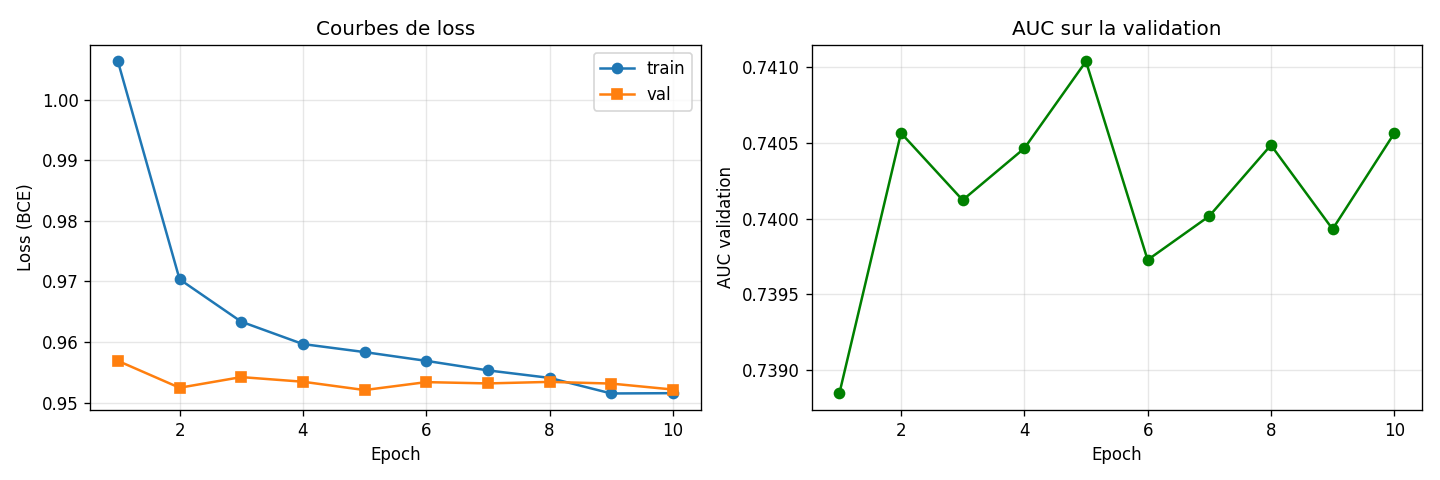

In [1]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['epoch'], history['train_loss'], label='train', marker='o')
axes[0].plot(history['epoch'], history['val_loss'], label='val', marker='s')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss (BCE)')
axes[0].set_title('Courbes de loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history['epoch'], history['val_auc'], color='green', marker='o')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUC validation')
axes[1].set_title('AUC sur la validation'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('../outputs/figures/mlp_curves.png', dpi=120); plt.show()

## Conclusion de la Partie 2

Le MLP atteint **AUC = 0.7316** sur le test, en 11 secondes.

Ce résultat est **du même ordre** que les modèles ML classiques de la Partie 1. Le Deep Learning **n'apporte pas de gain significatif** sur ce type de données tabulaires — confirmation expérimentale de **Gunnarsson et al. (2021)**.

La comparaison rigoureuse des quatre modèles est faite dans le notebook **`04_comparison.ipynb`**.